# 01 · Ingestão, ETL e engenharia de atributos

**Problema:** prever se um cliente vai contratar um depósito a prazo após uma ligação de telemarketing (*Bank Marketing*, UCI, licença CC BY 4.0). Classificação binária, alvo `y`.

**Unidade de observação:** um contato telefônico com um cliente em uma campanha (mai/2008 a nov/2010).

**Valor para o negócio:** ranquear os clientes para que o banco ligue primeiro para quem tem mais chance de contratar, reduzindo custo de ligações improdutivas.

**Desenho da avaliação (definido antes de qualquer treino, em `config/config.yaml`):**

| Item | Definição | Justificativa |
|---|---|---|
| Métrica principal | AUC-PR (*average precision*), maximizar | Classe positiva rara (~11%); não depende de limiar |
| Particionamento | 70% treino · 15% validação · 15% teste, por hash do `registro_id` | Partições estáveis entre ciclos: nenhum modelo, nem o vigente de ciclos anteriores, treina com dados de validação/teste |
| Competição A × B | Validação cruzada estratificada (5 folds) no treino | Decisão recorrente sem tocar no teste |
| Promoção | Validação do ciclo, vencedor × vigente | Mesmo conjunto para os dois modelos |
| Teste | Só avaliação final do modelo vigente | Reservado, nunca usado em decisões |
| Chegada de dados | 1 lote por ciclo = próximos 3 meses de campanha, em ordem cronológica | Simula o CRM entregando novos contatos; mudanças no tempo são vigiadas pelo monitor de drift |

> **Por que não um corte temporal no teste?** Testamos: como o volume de contatos se concentra em 2008-2009 e o perfil da campanha muda muito depois, o trecho "mais recente" sempre cai em um regime que o modelo nunca viu e a AUC fica perto de 0,5 em todos os ciclos. Cada contato é um evento independente (não uma série temporal), então a ordem do tempo é respeitada onde importa: na chegada dos dados e no monitoramento de drift.

Este notebook abre o ciclo: gera `cycle_id` e `data_version`, que todos os notebooks seguintes compartilham.

In [1]:
import os, sys, warnings
from pathlib import Path
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
warnings.filterwarnings("ignore", category=UserWarning)
# Localiza a raiz do repositório e torna o pacote src importável
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
os.chdir(RAIZ); sys.path.insert(0, str(RAIZ))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.utils import carregar_config, configurar_mlflow, ler_contexto, atualizar_contexto, tags_ciclo, caminho, salvar_json
cfg = carregar_config()
pd.set_option("display.width", 160)

## 1. Abertura do ciclo e ingestão do lote novo

In [2]:
from src.utils import info_execucao
from src.ingestao import ingerir_proximo_lote, carregar_acumulado, data_version, lotes_ingeridos
from src.promocao import HISTORICO_DECISOES

lote = ingerir_proximo_lote(cfg)
n_ciclo = (len(pd.read_csv(caminho(HISTORICO_DECISOES))) if caminho(HISTORICO_DECISOES).exists() else 0) + 1
execucao = info_execucao()
cycle_id = f"c{n_ciclo:03d}-{execucao['iniciado_em'][:16].replace('-', '').replace(':', '').replace('T', '-')}"
ctx = {"cycle_id": cycle_id, "data_version": data_version(cfg), "execucao": execucao, "lote": lote}
salvar_json(ctx, caminho(cfg["dados"]["state_dir"]) / "ciclo_atual.json")

print(f"cycle_id     : {ctx['cycle_id']}")
print(f"data_version : {ctx['data_version']}")
print(f"gatilho      : {execucao['gatilho']}")
if lote["novo"]:
    print(f"lote novo    : #{lote['lote']} | períodos {lote['periodos']} | {lote['linhas']} registros")
else:
    print("Nenhum lote novo na fonte: o ciclo será executado com os dados já disponíveis.")
display(pd.DataFrame(lotes_ingeridos(cfg)))

cycle_id     : c002-20261117-1951
data_version : v002-db4f8bd6
gatilho      : schedule
lote novo    : #1 | períodos ['2008-12', '2009-03', '2009-04'] | 2750 registros


,lote,arquivo,periodos,linhas,sha256,ingerido_em
0,0,data/raw/lote_000.csv,"[2008-05, 2008-06, 2008-07, 2008-08, 2008-10, ...",27680,9f2fcaccde47,2026-11-16T21:02:46+00:00
1,1,data/raw/lote_001.csv,"[2008-12, 2009-03, 2009-04]",2750,19adc497396f,2026-11-17T19:51:41+00:00


## 2. Diagnóstico de qualidade (antes)

In [3]:
from src.preprocessamento import validar, limpar_e_criar_atributos, separar_xy, particionar

bruto = carregar_acumulado(cfg)
diag_antes = validar(bruto, cfg)   # erros graves interrompem o pipeline aqui
print(json.dumps(diag_antes, indent=2, ensure_ascii=False))
display(bruto.head())

{
  "linhas": 30430,
  "duplicatas": 9,
  "nulos": 0,
  "unknown_por_coluna": {
    "job": 258,
    "marital": 51,
    "education": 1257,
    "default": 7532,
    "housing": 733,
    "loan": 733
  },
  "taxa_positiva": 0.06266841932303648
}


,registro_id,age,job,marital,education,default,housing,loan,contact,month,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,periodo
0,0,56,housemaid,married,basic.4y,no,no,no,telephone,may,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2008-05
1,1,57,services,married,high.school,unknown,no,no,telephone,may,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2008-05
2,2,37,services,married,high.school,no,yes,no,telephone,may,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2008-05
3,3,40,admin.,married,basic.6y,no,no,no,telephone,may,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2008-05
4,4,56,services,married,high.school,no,no,yes,telephone,may,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2008-05


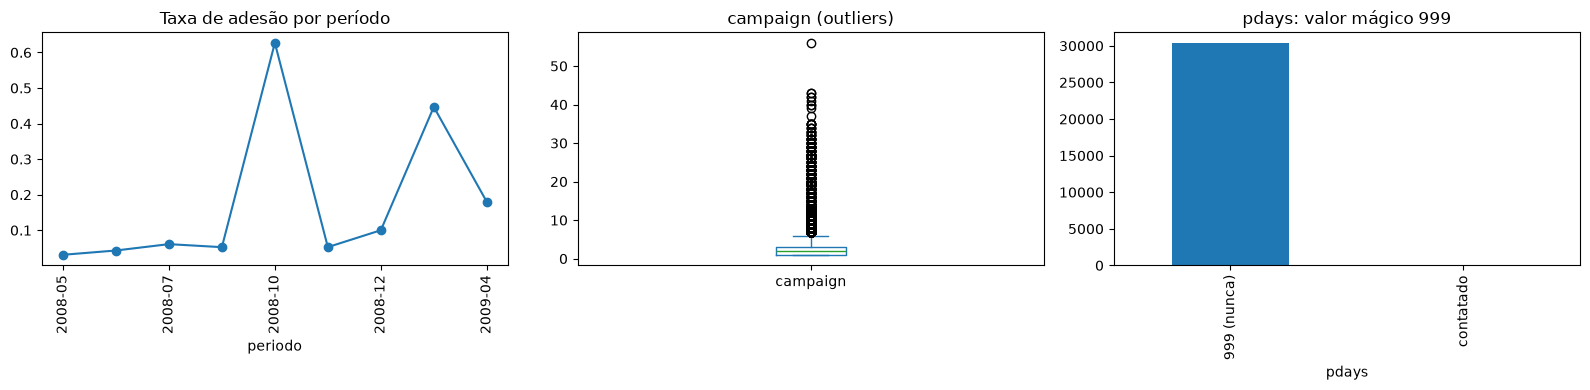

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
bruto.groupby("periodo")["y"].apply(lambda s: (s == "yes").mean()).plot(ax=ax[0], marker="o")
ax[0].set_title("Taxa de adesão por período"); ax[0].tick_params(axis="x", rotation=90)
bruto["campaign"].plot.box(ax=ax[1]); ax[1].set_title("campaign (outliers)")
(bruto["pdays"] == 999).value_counts().rename({True: "999 (nunca)", False: "contatado"}).plot.bar(ax=ax[2])
ax[2].set_title("pdays: valor mágico 999")
plt.tight_layout(); plt.show()

## 3. Limpeza e engenharia de atributos

Transformações **determinísticas** (não aprendem nada com os dados, então podem ser aplicadas antes do split sem vazamento):

| Tratamento | Motivo |
|---|---|
| Remover duplicatas exatas | Mesmo contato registrado duas vezes |
| Remover `duration` | Só é conhecida **depois** da ligação → vazamento (alertado pela própria UCI) |
| `pdays = 999` → `contatado_antes` (0/1) e `pdays` vazio | 999 é um código, não um número; distorceria escala e outliers |
| `contatos_totais = campaign + previous` | Intensidade total de contato com o cliente |
| `faixa_etaria` | Adesão não é linear na idade (jovens e aposentados aderem mais) |
| `unknown` mantido como categoria | A falta de informação é, por si, informativa |

Tudo que **aprende** com os dados (imputação, limites de outliers por percentil, padronização, one-hot) fica no `Pipeline` e é ajustado só no treino, dentro de cada notebook seguinte.

In [5]:
limpo = limpar_e_criar_atributos(bruto, cfg)
X_tmp, _ = separar_xy(limpo, cfg)
# duplicatas reais = registros idênticos na base original (sem duration, contatos
# diferentes podem ficar iguais; esses NÃO são duplicatas e são mantidos)
mantidos = bruto[bruto["registro_id"].isin(limpo["registro_id"])]
diag_depois = {"linhas": len(limpo), "duplicatas": int(mantidos.drop(columns=["registro_id", "periodo"]).duplicated().sum()),
               "colunas": X_tmp.shape[1], "taxa_positiva": float(limpo["y"].mean())}
display(pd.DataFrame({"antes": {k: diag_antes[k] for k in ["linhas", "duplicatas", "taxa_positiva"]},
                      "depois": {k: diag_depois[k] for k in ["linhas", "duplicatas", "taxa_positiva"]}}))
print("Atributos de entrada:", list(X_tmp.columns))

,antes,depois
linhas,30430.000000,30421.000000
duplicatas,9.000000,0.000000
taxa_positiva,0.062668,0.062687


Atributos de entrada: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'contatado_antes', 'contatos_totais', 'faixa_etaria']


## 4. Particionamento estável (hash do registro_id)

In [6]:
treino, validacao, teste = particionar(limpo, cfg)
proc = caminho(cfg["dados"]["processed_dir"]); proc.mkdir(parents=True, exist_ok=True)
for nome, parte in [("treino", treino), ("validacao", validacao), ("teste", teste)]:
    parte.to_csv(proc / f"{nome}.csv", index=False)

resumo_split = pd.DataFrame({
    nome: {"linhas": len(p), "de": p["periodo"].min(), "até": p["periodo"].max(), "taxa_positiva": round(p["y"].mean(), 4)}
    for nome, p in [("treino", treino), ("validacao", validacao), ("teste", teste)]}).T
display(resumo_split)

,linhas,de,até,taxa_positiva
treino,21495,2008-05,2009-04,0.0631
validacao,4468,2008-05,2009-04,0.0575
teste,4458,2008-05,2009-04,0.0659


## 5. Monitoramento de drift (Critério 10)

Compara a distribuição de cada atributo do **lote que acabou de chegar** com a dos dados já conhecidos, pelo PSI. Se algum atributo passar de 0,25, o ciclo emite um alerta (anotação no GitHub Actions + resumo da execução) e o alerta fica registrado no MLflow e no manifesto do modelo.

,feature,psi,status
0,month,16.4750,ALERTA
1,emp.var.rate,9.6087,ALERTA
2,cons.price.idx,8.7545,ALERTA
3,euribor3m,8.7272,ALERTA
4,nr.employed,7.3037,ALERTA
5,cons.conf.idx,7.1474,ALERTA
6,pdays,6.9477,ALERTA
7,contact,1.0932,ALERTA
8,poutcome,0.5681,ALERTA
9,faixa_etaria,0.2432,ATENÇÃO


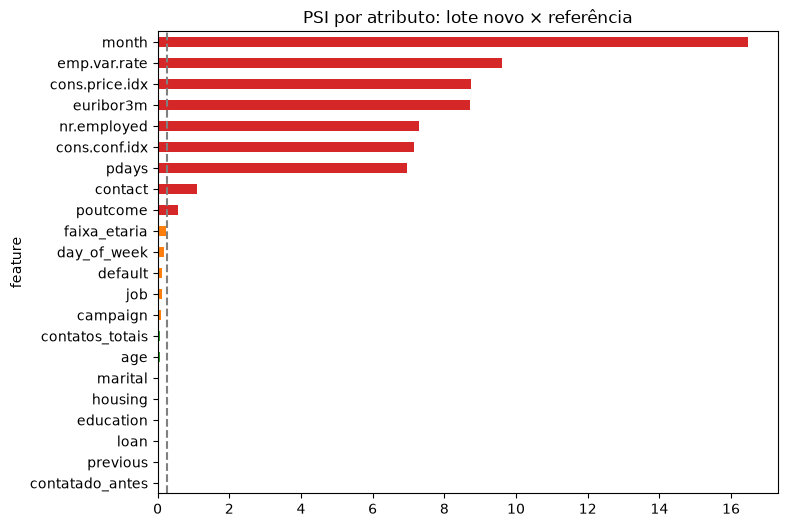

ALERTA: Ciclo c002-20261117-1951: drift relevante (PSI >= 0.25) em month, emp.var.rate, cons.price.idx, euribor3m, nr.employed, cons.conf.idx, pdays, contact, poutcome
::warning title=Drift detectado::Ciclo c002-20261117-1951: drift relevante (PSI >= 0.25) em month, emp.var.rate, cons.price.idx, euribor3m, nr.employed, cons.conf.idx, pdays, contact, poutcome


In [7]:
from src.drift import relatorio_drift
from src.utils import resumo_github, aviso_github

drift = None
if lote["novo"] and lote["lote"] > 0:
    ids_novos = set(pd.read_csv(caminho(lote["arquivo"]))["registro_id"])
    ref = limpo[~limpo["registro_id"].isin(ids_novos)]
    novo = limpo[limpo["registro_id"].isin(ids_novos)]
    Xr, _ = separar_xy(ref, cfg); Xn, _ = separar_xy(novo, cfg)
    drift = relatorio_drift(Xr, Xn, cfg)
    display(drift)
    cores = drift["status"].map({"ALERTA": "#d62728", "ATENÇÃO": "#ff7f0e", "estável": "#2ca02c"})
    drift.plot.barh(x="feature", y="psi", color=cores, legend=False, figsize=(8, 6))
    plt.axvline(cfg["drift"]["psi_alerta"], ls="--", c="gray"); plt.gca().invert_yaxis()
    plt.title("PSI por atributo: lote novo × referência"); plt.show()
else:
    print("Sem lote novo para comparar (primeiro ciclo ou fonte esgotada): drift não calculado.")

alertas = [] if drift is None else drift.loc[drift["status"] == "ALERTA", "feature"].tolist()
if alertas:
    msg = f"Ciclo {cycle_id}: drift relevante (PSI >= {cfg['drift']['psi_alerta']}) em {', '.join(alertas)}"
    print("ALERTA:", msg); aviso_github(msg)
ctx = atualizar_contexto(cfg, drift_alerta=bool(alertas), features_com_drift=alertas,
                         psi_max=None if drift is None else float(drift["psi"].max()))

## 6. Registro no MLflow

In [8]:
mlflow = configurar_mlflow(cfg)
with mlflow.start_run(run_name=f"{cycle_id}_01_etl", tags=tags_ciclo(ctx, "01_etl")) as run:
    mlflow.log_params({"lote": lote.get("lote"), "lote_novo": lote["novo"], "periodos_lote": ",".join(lote["periodos"]),
                       "split": "hash registro_id 70/15/15", "colunas_removidas": ",".join(cfg["dados"]["colunas_removidas"])})
    mlflow.log_metrics({"linhas_brutas": diag_antes["linhas"], "duplicatas_removidas": diag_antes["duplicatas"],
                        "linhas_treino": len(treino), "linhas_validacao": len(validacao), "linhas_teste": len(teste),
                        "taxa_positiva_treino": treino["y"].mean(), "taxa_positiva_teste": teste["y"].mean(),
                        "drift_alertas": len(alertas)})
    if drift is not None:
        mlflow.log_metric("psi_max", float(drift["psi"].max()))
        mlflow.log_table(drift, "drift_psi.json")
    mlflow.log_dict(diag_antes, "diagnostico_qualidade.json")
    atualizar_contexto(cfg, run_etl=run.info.run_id)

resumo_github(f"## Ciclo `{cycle_id}`\n\n- data_version: `{ctx['data_version']}`\n- gatilho: `{execucao['gatilho']}`\n"
              f"- lote: {lote.get('lote')} {lote['periodos']} ({lote['linhas']} registros)\n"
              f"- drift: {'⚠️ ' + ', '.join(alertas) if alertas else 'sem alertas'}\n")
print("ETL concluído:", cycle_id)

ETL concluído: c002-20261117-1951
